In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Importing the ncessary modules
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device
from PLsim.system.lantern import generate_unitary_matrix

import hcipy as hc
import numpy as np
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import pandas as pd
from tqdm import tqdm

# Custom modules
import functions

# Formatting the plots
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

## Defining input parameters and constants

In [2]:
# Separations
THETA_MIN = -100 # [mas]
THETA_MAX = 100 # [mas]
THETA_NUM = 100
THETA_RANGE = np.linspace(THETA_MIN, THETA_MAX, THETA_NUM)

# Masses
M2_MIN = 0.01 # [M_1]
M2_MAX = 1 # [M_1]
M2_NUM = 99
M2_RANGE = np.linspace(M2_MIN, M2_MAX, M2_NUM)

# Constants
MAS_TO_RAD = 1e-3/206265 # [rad/mas]
DIVISOR_OUTPUT = 0

# Photonic lantern attributes
N_DIM = 65 # Number of pixels in pupil grid
DIAMETER = 10 # [m], diameter of telescope aperture for pupil
FOCAL_RESOLUTION = 1e-6 # [m], resolution of focal grid (make sure this samples LP modes enough but also not truncate the outer parts)
FOCAL_LENGTH = 40 # [m], focal length of telescope (initial value, OTF.from_fiber_params will find an optimal focal ratio)

# Fiber attributes
N_CORE = 1.444 # Index of refraction of the core
N_CLAD = 1.444 - 5.5e-3 # Index of refraction of the cladding
R_CORE = 10e-6 # [m], core radius

# Wavelengths
N_SPEC = 150 # Number of wavelength channels
WAV_MIDDLE = 1282.8 # [nm], Paschen beta line
WAV_WIDTH = 0.1 # [nm]
WAV_BANDWIDTH = 10*WAV_WIDTH # [nm]
WAV_RANGE = np.linspace(WAV_MIDDLE - WAV_BANDWIDTH/2, WAV_MIDDLE + WAV_BANDWIDTH/2, N_SPEC)

## Creating the photonic lantern model

In [3]:
# Creating the photonic lantern model
(pupil_grid, focal_grid, aperture, otf, N_OUTPUTS, matrix, device, scene, scene_projector) = functions.create_photonic_lantern_device(
    N_DIM=N_DIM,
    DIAMETER=DIAMETER,
    FOCAL_RESOLUTION=FOCAL_RESOLUTION,
    WAV_MIDDLE=WAV_MIDDLE,
    N_CORE=N_CORE,
    N_CLAD=N_CLAD,
    R_CORE=R_CORE,
    FOCAL_LENGTH=FOCAL_LENGTH,
    N_SPEC=N_SPEC
)

Created pupil grid
Created focal grid

Fiber details:
n_core: 1.444
n_clad: 1.4385
r_core: 1e-05 m
ref_wavelength: 1.2828e-06 m

Created aperture
Supported modes:  ['LP01', 'LP11a', 'LP11b', 'LP21a', 'LP21b', 'LP02', 'LP31a', 'LP31b', 'LP12a', 'LP12b']
Number of modes:  10
Created optical transfer function

Computed optical transfer function

Generated unitary matrix of shape: (N_SPEC x N_OUTPUTS x N_OUTPUTS) -> (150, 10, 10)

Device initialized with:
  Lantern matrices: (150, 10, 10)
  PIC matrices: None
  Wavelengths: 150
Initialized device with the unitary matrix

Defined scene
Projected scene onto optical transfer function



## Creating spectra of the two stars

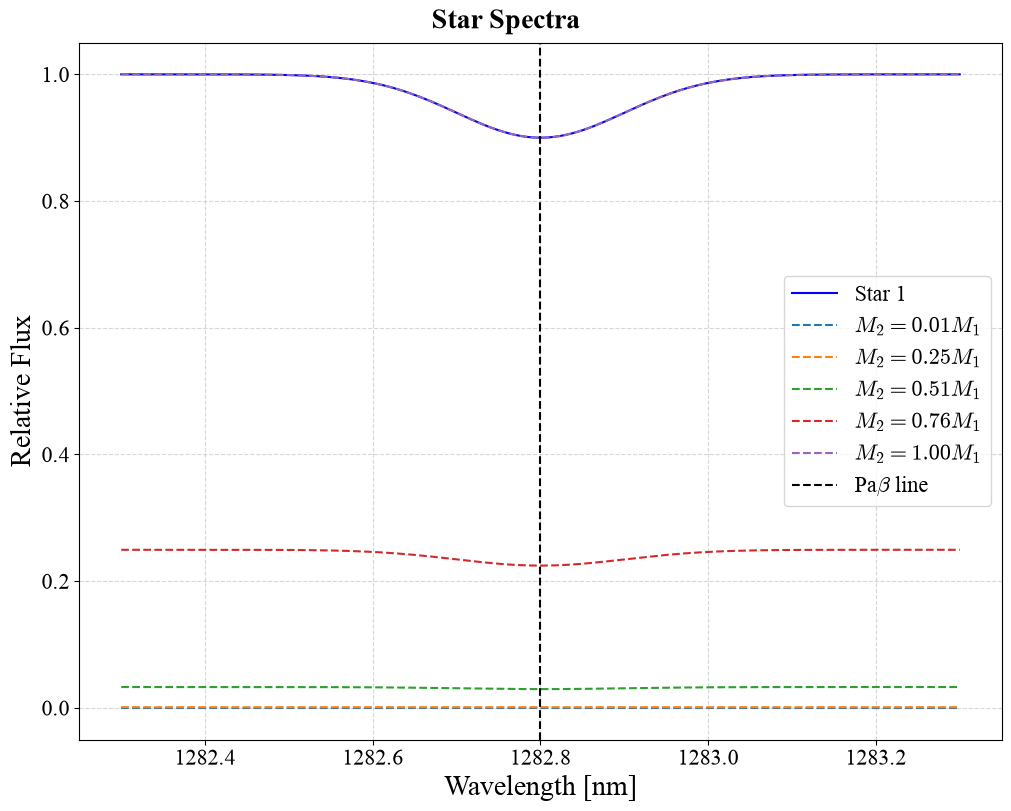

In [11]:
# Mass of the stars
M_1 = 1 # [M_1]
M_2 = M2_RANGE # [M_1]

# Flux of the continuum of star 1
F_1 = 1

# Flux of star 2
F_2 = F_1 / functions.M_L_relation(M_1, M_2).reshape(-1, 1)

# Flux multiplier of the line
a_line_1 = 0.9 # Paschen beta line is 90% of the continuum normally...
a_line_2 = 0.9 # Paschen beta line is 90% of the continuum normally...

# Flux of the line of star 1
F_line_1 = a_line_1 * F_1

# Flux of the line of star 2
F_line_2 = a_line_2 * F_2

# Spectrum of star 1
star1_spectrum = F_1 * np.ones_like(WAV_RANGE)
star1_spectrum -= (F_1 - F_line_1) * np.exp(-0.5 * (WAV_RANGE - WAV_MIDDLE)**2 / WAV_WIDTH**2)

# Spectrum of star 2
star2_spectrum = np.dot(F_2, np.ones_like(WAV_RANGE).reshape(1, -1))
star2_spectrum -= (F_2 - F_line_2) * np.exp(-0.5 * (WAV_RANGE - WAV_MIDDLE)**2 / WAV_WIDTH**2).reshape(1, -1)

# Plotting the spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Star Spectra')

ax.plot(WAV_RANGE, star1_spectrum, label='Star 1', color='b', linestyle='-')

for i in range(len(M_2)):
    if i == 0 or i == len(M_2)//4 or i == len(M_2)//2 or i == 3*len(M_2)//4 or i == len(M_2) - 1:
        ax.plot(WAV_RANGE, star2_spectrum[i], label=f'$M_2 = {M_2[i]:.2f} M_1$', linestyle='--')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

## Testing normalization scheme #1:
1. Calculate the continuum intensity for every output (far away from any spectral features):
$$
    I_{n, \infty} \equiv \lim_{\lambda \to \infty} I_{n, \lambda}
$$

<!-- 2. Divide all output intensities by one of the output intensities:
$$
    I_{n, \text{norm}} = \frac{I_{n, \lambda}}{I_{0, \lambda}}
$$ -->

2. Calculate the integral to find a single number for the total normalized intensity at each output:
$$
    I_{n, \text{tot}} \equiv  \int{\left|\frac{I_{n, \lambda} - I_{n, \infty}}{I_{0, \lambda}}\right| d\lambda}
$$

In [12]:
def calculate_normalized_intensities(outputs, divisor_output, wav_range) -> np.ndarray:
    '''
    Calculates the normalized intensities of each output given photonic lantern outputs and divisor output.as_integer_ratio

    Parameters
    ----------
    outputs : np.ndarray 
        Output from `device.calculate_outputs()` [number of wavelength channels, number of outputs]
    divisor_output : int
        Index of the output to normalize by
    wav_range : np.ndarray
        Wavelength range [number of wavelength channels]

    Returns
    -------
    normalized_intensities : np.ndarray
        Normalized intensities of each output [number of outputs]
    '''
    # Initializing array to store the total normalized intensities
    tot_norm_outputs = []

    # Iterating through each photonic lantern output
    for i in range(outputs.shape[1]):
        # Calculating the continuum intensity for the output (basically far from the spectral features)
        continuum_intensity = (outputs[0, i] + outputs[-1, i]) / 2

        # Calculating the total normalized intensity for the output
        integral = np.sum( np.abs((outputs[:, i] - continuum_intensity)/outputs[:, divisor_output] * (wav_range[1] - wav_range[0])) )

        tot_norm_outputs.append(integral)

    return np.array(tot_norm_outputs)

In [13]:
# Star 1 position
star1_x = np.zeros_like(M2_RANGE)
star1_y = np.zeros_like(M2_RANGE)

# Star 2 position
star2_x = (30 * MAS_TO_RAD) + np.zeros_like(M2_RANGE)
star2_y = np.zeros_like(M2_RANGE)

# Storing the total normalized intensities for each output for the combined star field
combined_total_normalized_intensities = []

# Defining the output to normalize by
divisor_output = 0

# Iterating through positions
for i in tqdm(range(len(M2_RANGE))):

    # Projecting the star onto the OTF
    star1_projected = scene_projector.compute_point(star1_x[i], star1_y[i]).repeat(N_SPEC, axis=2) * star1_spectrum[np.newaxis, np.newaxis]
    star2_projected = scene_projector.compute_point(star2_x[i], star2_y[i]).repeat(N_SPEC, axis=2) * star2_spectrum[i, :][np.newaxis, np.newaxis]

    # Combining the projected star fields
    combined_projected = star1_projected + star2_projected

    # Passing the combined projected star through the device
    combined_outputs = device.calculate_outputs(combined_projected.transpose(2, 0, 1))

    rng = np.random.default_rng(0)
    NOISE = 1e-3 # Fractional noise per channel and port

    # Passing the combined projected star through the device
    combined_outputs = device.calculate_outputs(combined_projected.transpose(2, 0, 1))
    combined_outputs *= 1 + NOISE * rng.standard_normal(combined_outputs.shape)

    # Storing the total intensities for each output for the combined star field
    combined_total_normalized_intensities.append(calculate_normalized_intensities(combined_outputs, divisor_output, WAV_RANGE))

combined_total_normalized_intensities = np.array(combined_total_normalized_intensities)
print(f'Combined total normalized intensities shape: (M2_NUM x N_OUTPUTS) -> {combined_total_normalized_intensities.shape}')

diff_limit = 1.22 * WAV_MIDDLE*1e-9 / DIAMETER * 206265 * 1000 # [mas]
print(f'Diffraction limit: {diff_limit} mas')

  0%|          | 0/99 [00:00<?, ?it/s]

100%|██████████| 99/99 [00:00<00:00, 278.08it/s]

Combined total normalized intensities shape: (M2_NUM x N_OUTPUTS) -> (99, 10)
Diffraction limit: 32.280802524 mas


### Plotting results

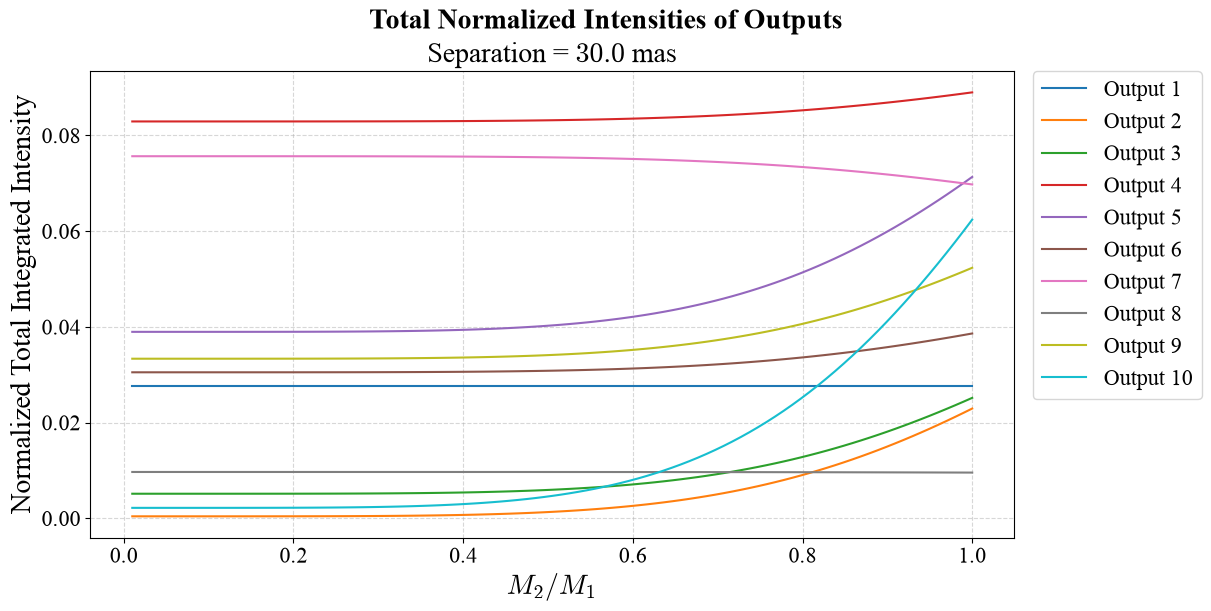

In [14]:
fig = plt.figure(figsize=(12, 6))
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Total Normalized Intensities of Outputs')

ax.set_title(f'Separation = ${star2_x[0]/MAS_TO_RAD:.1f}$ mas')

for i in range(N_OUTPUTS):
    ax.plot(M2_RANGE, combined_total_normalized_intensities[:, i], label=f'Output {i+1}')

ax.set_xlabel('$M_2/M_1$')
ax.set_ylabel('Normalized Total Integrated Intensity')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.show()

## Testing normalization scheme #2:
1. Compute output intensity as fractions of total intensity
$$
    f_n(\lambda) \equiv \frac{I_n(\lambda)}{\sum_m I_m(\lambda)}
$$

2. Compute continuum fraction of total intensity
$$
    f_{n, \infty} \equiv \lim_{\lambda \to \infty} f_n(\lambda)
$$

3. Compute integral of the difference between fractional intensities from continuum
$$
    S_n \equiv \int \left| f_n(\lambda) - f_{n, \infty} \right| d\lambda
$$

In [15]:
def calculate_signal(outputs, wav_range) -> np.ndarray:
    '''
    Calculates the signal of each output given photonic lantern outputs and divisor output.

    Parameters
    ----------
    outputs : np.ndarray 
        Output from `device.calculate_outputs()` [number of wavelength channels, number of outputs]
    wav_range : np.ndarray
        Wavelength range [number of wavelength channels]

    Returns
    -------
    signals : np.ndarray
        Signals of each output [number of outputs]
    '''
    # Initializing array to store the signals
    signals = []

    # Finding the total intensity at each wavelength channel for all the outputs
    total_intensity = np.sum(outputs, axis=1)

    # Iterating through each photonic lantern output
    for i in range(outputs.shape[1]):
        # Calculating fractional intensity of the port (port intensity/total intensity)
        fractional_intensity = outputs[:, i] / total_intensity

        # Calculating the continuum fractional intensity for the output (basically far from the spectral features)
        continuum_fractional_intensity = (fractional_intensity[0] + fractional_intensity[-1]) / 2

        # Calculating the signal for the output
        integral = np.sum( np.abs((fractional_intensity - continuum_fractional_intensity) * (wav_range[1] - wav_range[0])) )

        signals.append(integral)

    return np.array(signals)

In [16]:
# Star 1 position
star1_x = np.zeros_like(M2_RANGE)
star1_y = np.zeros_like(M2_RANGE)

# Star 2 position
star2_x = (30 * MAS_TO_RAD) + np.zeros_like(M2_RANGE)
star2_y = np.zeros_like(M2_RANGE)

# Storing the total normalized intensities for each output for the combined star field
signals = []

# Iterating through positions
for i in tqdm(range(len(M2_RANGE))):
    # Projecting the star onto the OTF
    star1_projected = scene_projector.compute_point(star1_x[i], star1_y[i]).repeat(N_SPEC, axis=2) * star1_spectrum[np.newaxis, np.newaxis]
    star2_projected = scene_projector.compute_point(star2_x[i], star2_y[i]).repeat(N_SPEC, axis=2) * star2_spectrum[i, :][np.newaxis, np.newaxis]

    # Combining the projected star fields
    combined_projected = star1_projected + star2_projected

    # Passing the combined projected star through the device
    combined_outputs = device.calculate_outputs(combined_projected.transpose(2, 0, 1))

    rng = np.random.default_rng(0)
    NOISE = 1e-3 # Fractional noise per channel and port

    # Passing the combined projected star through the device
    combined_outputs = device.calculate_outputs(combined_projected.transpose(2, 0, 1))
    # combined_outputs *= 1 + NOISE * rng.standard_normal(combined_outputs.shape)

    # Storing the total intensities for each output for the combined star field
    signals.append(calculate_signal(combined_outputs, WAV_RANGE))

signals = np.array(signals)
print(f'Combined signal shape: (M2_NUM x N_OUTPUTS) -> {signals.shape}')

diff_limit = 1.22 * WAV_MIDDLE*1e-9 / DIAMETER * 206265 * 1000 # [mas]
print(f'Diffraction limit: {diff_limit} mas')

100%|██████████| 99/99 [00:00<00:00, 213.72it/s]

Combined signal shape: (M2_NUM x N_OUTPUTS) -> (99, 10)
Diffraction limit: 32.280802524 mas


### Plotting results

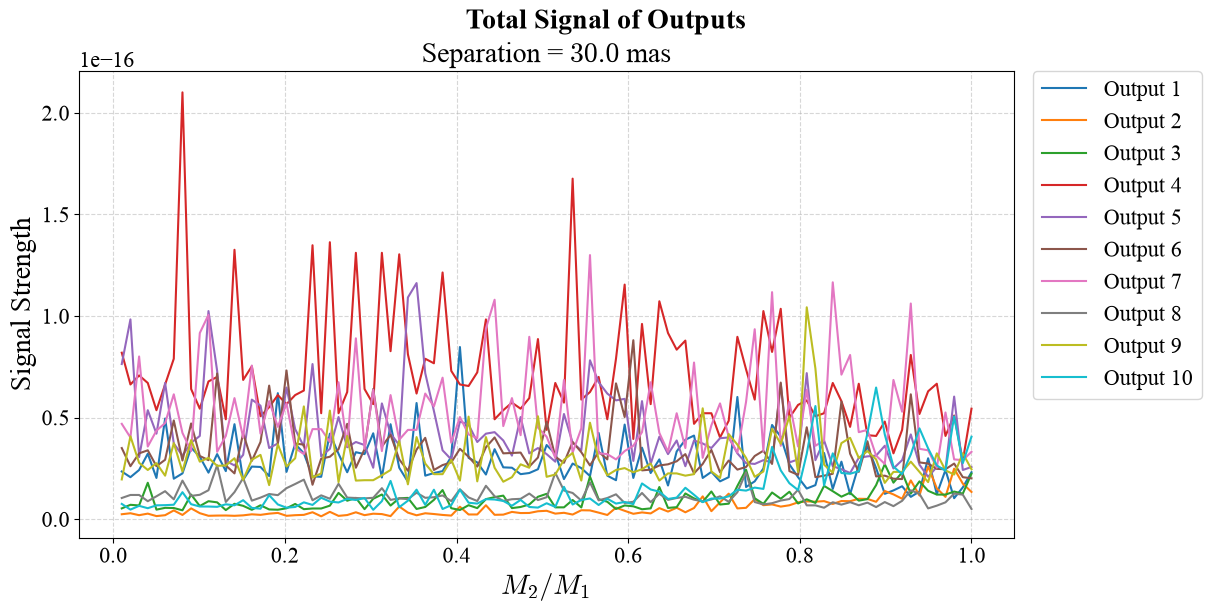

In [17]:
fig = plt.figure(figsize=(12, 6))
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Total Signal of Outputs')

ax.set_title(f'Separation = ${star2_x[0]/MAS_TO_RAD:.1f}$ mas')

for i in range(N_OUTPUTS):
    ax.plot(M2_RANGE, signals[:, i], label=f'Output {i+1}')

ax.set_xlabel('$M_2/M_1$')
ax.set_ylabel('Signal Strength')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.show()

## Testing normalization scheme #3:
- Fit the signal of a single star to the $f_n(\lambda)$ curve (as a function of position)
- Compute residuals from the fit
- If the residuals are above some tolerance, then a single star is not enough to fully define the observation

### Defining star spectra

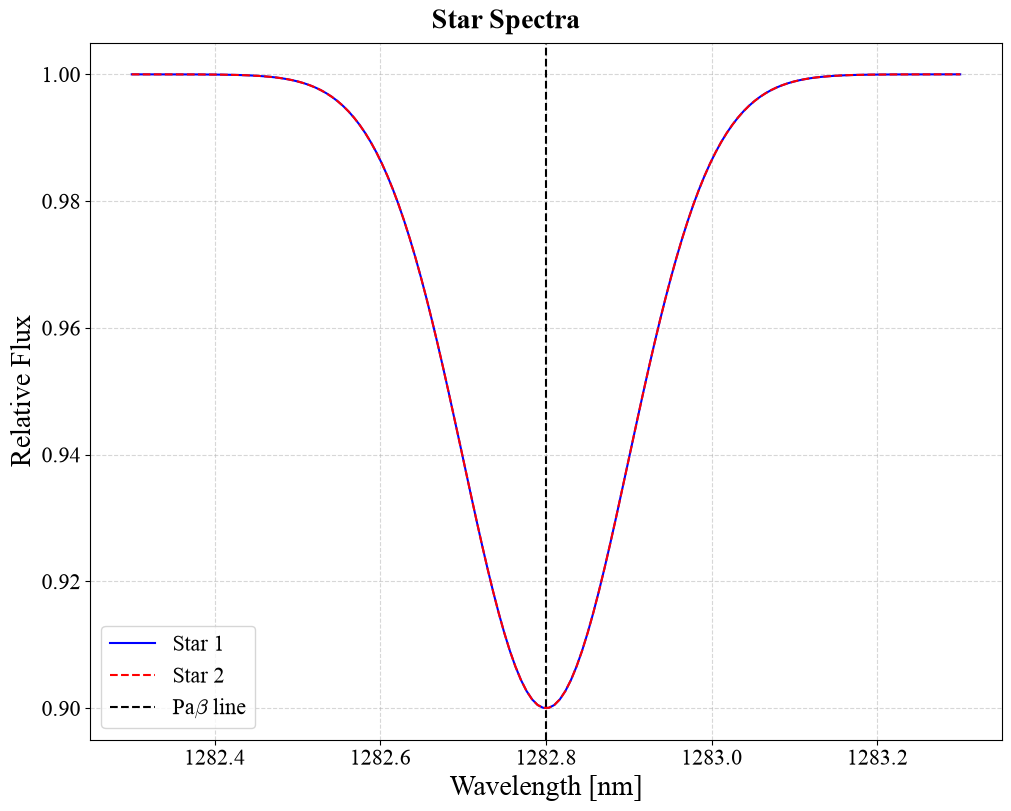

In [16]:
# Mass of the stars
M_1 = 1 # [M_1]
M_2 = 1 # [M_1]

# Flux of the continuum of star 1
F_1 = 1

# Flux of star 2
F_2 = F_1 / functions.M_L_relation(M_1, M_2)

# Flux multiplier of the line
a_line_1 = 0.9
a_line_2 = 0.9

# Flux of the line of star 1
F_line_1 = a_line_1 * F_1

# Flux of the line of star 2
F_line_2 = a_line_2 * F_2

# Spectrum of star 1
star1_spectrum = F_1 * np.ones_like(WAV_RANGE)
star1_spectrum -= (F_1 - F_line_1) * np.exp(-0.5 * (WAV_RANGE - WAV_MIDDLE)**2 / WAV_WIDTH**2)

# Spectrum of star 2
star2_spectrum = np.dot(F_2, np.ones_like(WAV_RANGE))
star2_spectrum -= (F_2 - F_line_2) * np.exp(-0.5 * (WAV_RANGE - (WAV_MIDDLE))**2 / WAV_WIDTH**2)

# Plotting the spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Star Spectra')

ax.plot(WAV_RANGE, star1_spectrum, label='Star 1', color='b', linestyle='-')
ax.plot(WAV_RANGE, star2_spectrum, label='Star 2', color='r', linestyle='--')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

### Creating input scene

(150, 10)
Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> (150, 10)


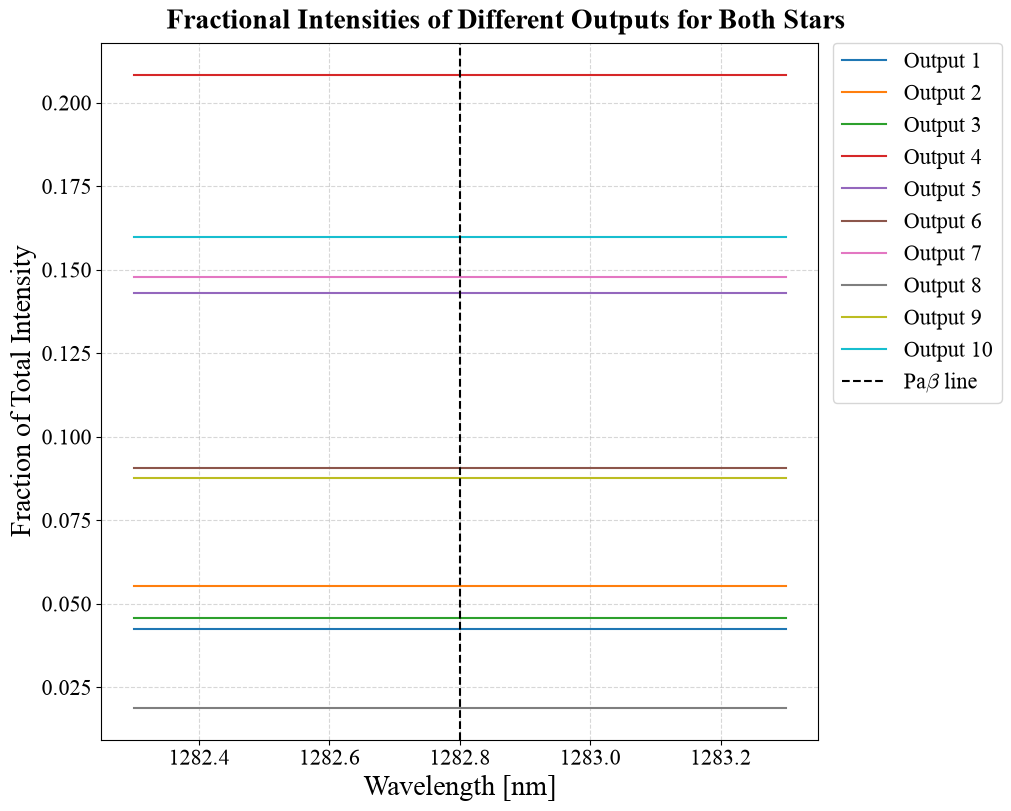

In [18]:
# Star 1 position
star1_x = 0
star1_y = 0

# Star 2 position
star2_x = 30 * MAS_TO_RAD
star2_y = 0

# Projecting the star onto the OTF
star1_projected = scene_projector.compute_point(star1_x, star1_y).repeat(N_SPEC, axis=2) * star1_spectrum[np.newaxis, np.newaxis]
star2_projected = scene_projector.compute_point(star2_x, star2_y).repeat(N_SPEC, axis=2) * star2_spectrum[np.newaxis, np.newaxis]

# Combining the projected star fields
combined_projected = star1_projected + star2_projected

rng = np.random.default_rng(0)
NOISE = 1e-3 # Fractional noise per channel and port

# Passing the combined projected star through the device
combined_outputs = device.calculate_outputs(combined_projected.transpose(2, 0, 1))
print(combined_outputs.shape)
# combined_outputs *= 1 + NOISE * rng.standard_normal(combined_outputs.shape)

# Computing the total intensities across all outputs as a function of wavelength
total_intensity = np.sum(combined_outputs, axis=1)

# Computing fractional intensities for the outputs
fractional_intensity = combined_outputs / total_intensity.reshape(-1, 1)

print(f'Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> {fractional_intensity.shape}')

fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Fractional Intensities of Different Outputs for Both Stars')

for i in range(N_OUTPUTS):
    ax.plot(WAV_RANGE, fractional_intensity[:, i], label=f'Output {i+1}')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Fraction of Total Intensity')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.show()

### Seeing what the outputs of a single star looks like

Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> (150, 10)


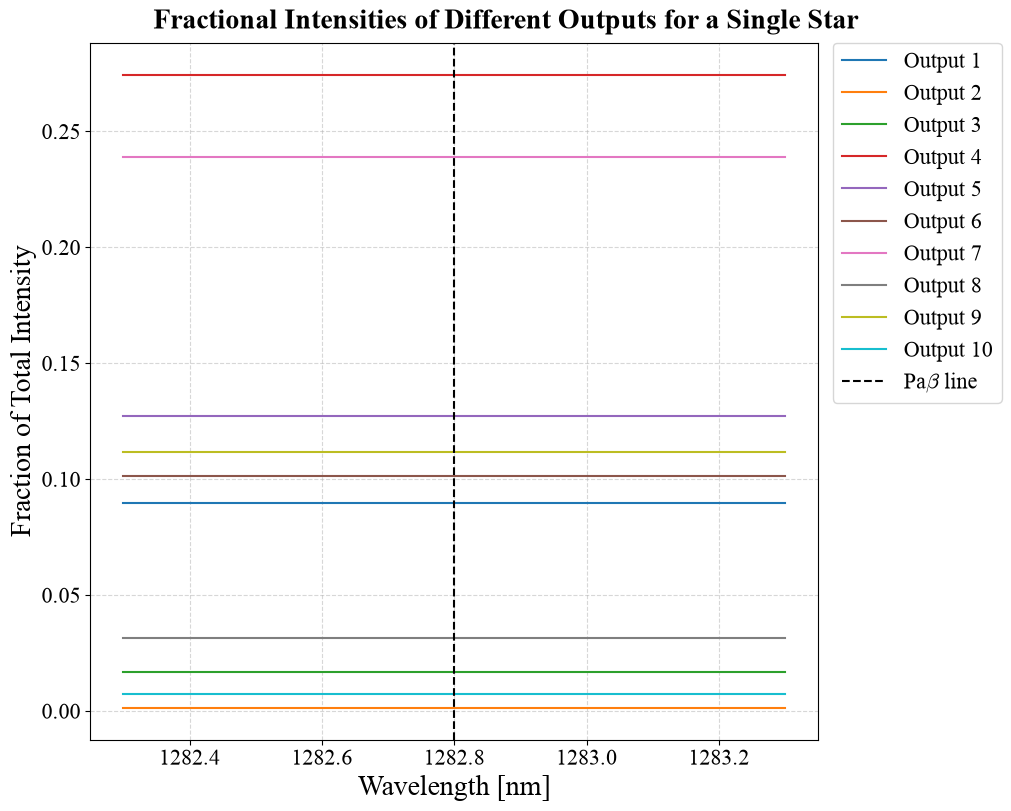

In [383]:
# Star 1 position
star1_x = 0
star1_y = 0

# Projecting the star onto the OTF
star1_projected = scene_projector.compute_point(star1_x, star1_y).repeat(N_SPEC, axis=2) * star1_spectrum[np.newaxis, np.newaxis]

# Passing the combined projected star through the device
star1_outputs = device.calculate_outputs(star1_projected.transpose(2, 0, 1))

# Computing the total intensities across all outputs as a function of wavelength
total_intensity_single = np.sum(star1_outputs, axis=1)

# Computing fractional intensities for the outputs
fractional_intensity_single = star1_outputs / total_intensity_single.reshape(-1, 1)

print(f'Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> {fractional_intensity_single.shape}')

fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Fractional Intensities of Different Outputs for a Single Star')

for i in range(N_OUTPUTS):
    ax.plot(WAV_RANGE, fractional_intensity_single[:, i], label=f'Output {i+1}')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Fraction of Total Intensity')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.show()

### Seeing the difference between the two outputs

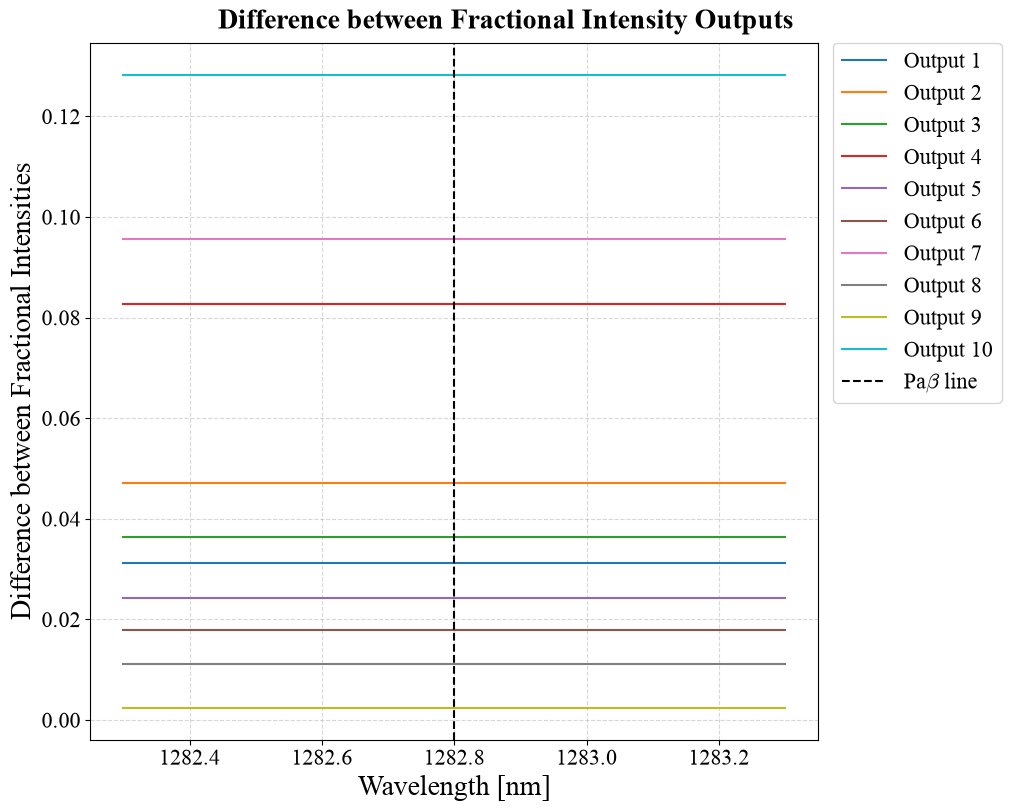

In [384]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Difference between Fractional Intensity Outputs')

for i in range(N_OUTPUTS):
    ax.plot(WAV_RANGE, np.abs(fractional_intensity[:, i] - fractional_intensity_single[:, i]), label=f'Output {i+1}')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Difference between Fractional Intensities')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.show()

### Creating optimization function to fit a single star to the signal
#### Two options:
Option 1:
$$
    \delta_n = \int \left| f_{n, \text{observed}}(\lambda) - f_{n, \text{single}}(\lambda) \right| d\lambda
$$
$$
    \delta \equiv \sqrt{\sum_n \delta_n^2}
$$
Option 2:
$$
    \delta_n(\lambda) = f_{n, \text{observed}}(\lambda) - f_{n, \text{single}}
$$
$$
    \delta \equiv \sum_n \sum_\lambda \delta_n^2(\lambda)
$$

Option 2 results in more smooth surface and bowls rather than cusps, so choosing Option 2 for the objective.

In [385]:
def single_optimization(x, observed_fractional_intensities) -> float:
    '''
    Calculates the error norm for a single star fit to observed photonic lantern output spectra.

    Parameters
    ----------
    x : tuple
        Tuple of (x, y) position for the first star in mas
    observed_fractional_intensities : np.ndarray
        (N_SPEC x N_OUTPUTS) matrix of observed fractional intensities from photonic lantern
    
    Returns
    -------
    delta : float
        Error norm of the errors of each port given by the integral over wavelengths of the difference between binary and single fractional intensities
    '''
    star1_x, star1_y = x

    # Projecting the star onto the OTF
    star1_projected = scene_projector.compute_point(star1_x * MAS_TO_RAD, star1_y * MAS_TO_RAD).repeat(N_SPEC, axis=2) * star1_spectrum[np.newaxis, np.newaxis]

    # Passing the combined projected star through the device
    star1_outputs = device.calculate_outputs(star1_projected.transpose(2, 0, 1))

    # Computing the total intensities across all outputs as a function of wavelength
    single_total_intensities = np.sum(star1_outputs, axis=1)

    # Computing fractional intensities for the outputs
    single_fractional_intensities = star1_outputs / single_total_intensities.reshape(-1, 1)

    # Calculating residuals
    residuals = observed_fractional_intensities - single_fractional_intensities # (N_SPEC, N_OUTPUTS)
    delta = np.sum(residuals**2)

    return delta

    # # Calculating error for each output by taking the integral with respect to wavelength
    # delta_n = np.zeros(N_OUTPUTS)

    # for i in range(N_OUTPUTS):
    #     integral = np.sum( np.abs((observed_fractional_intensities[:, i] - single_fractional_intensities[:, i]) * (WAV_RANGE[1] - WAV_RANGE[0])) )
    #     delta_n[i] = integral

    # # Calculating the sum in quadrature of the individual errors
    # delta = np.sum(delta_n**2)**0.5

    # return delta

### Finding global minimum of the error surface

In [386]:
# Defining bounds of the minimum finder by constraining the first star to (-50, 50) and (-50, 50) in x and y
bounds = [(-50, 50), (-50, 50)]

# Executing the operation
result = differential_evolution(lambda x: single_optimization(x, fractional_intensity), bounds)

print(f'GLobal minimum position: {result.x} mas')
print(f'Fuinction value at minimum position: {result.fun}')

GLobal minimum position: [ 33.70811207 -17.17388865] mas
Fuinction value at minimum position: 2.8814521349443094


### Seeing what the error surface looks like

In [387]:
# Defining a grid to try pass into the optimization function
xs = np.linspace(-50, 50, 100)
ys = np.linspace(-50, 50, 100)

XS, YS = np.meshgrid(xs, ys)

# Passing each position into the optimization function
deltas = np.zeros_like(XS)

for i, x in enumerate(xs):
    for j, y in enumerate(ys):
        delta = single_optimization((x, y), fractional_intensity)
        deltas[j, i] = delta

### Plotting error surface in 2D and 3D

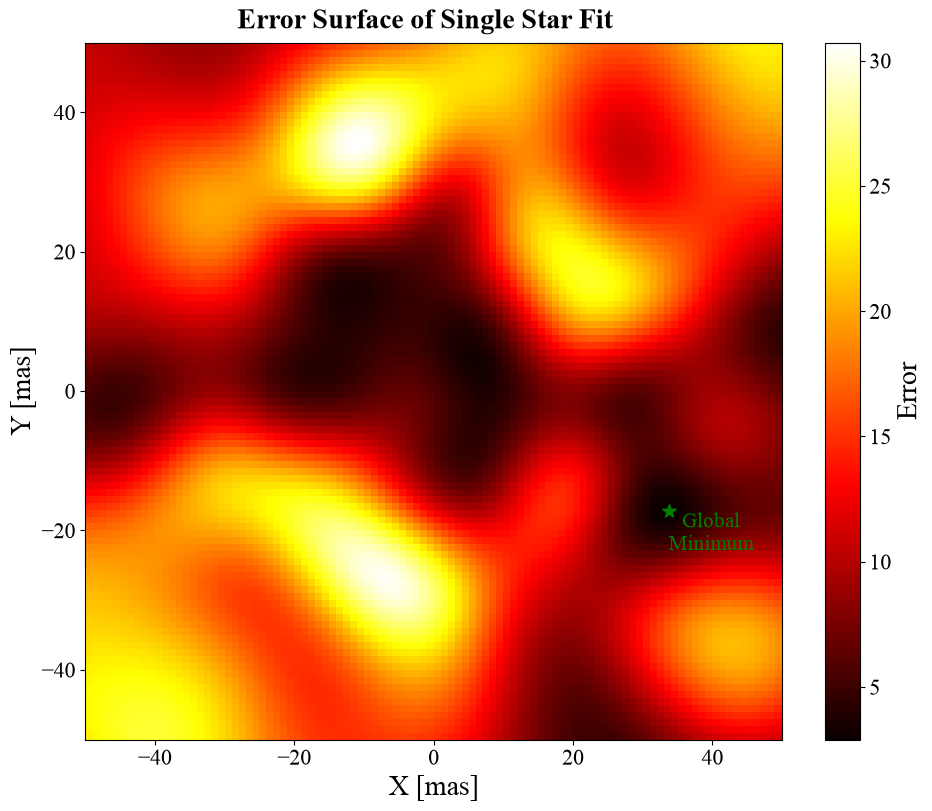

In [388]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Error Surface of Single Star Fit')

img = ax.imshow(deltas, origin='lower', extent=[xs[0], xs[-1], ys[0], ys[-1]], cmap='hot')

ax.scatter(result.x[0], result.x[1], marker='*', c='green', s=100)
ax.text(result.x[0], result.x[1], s='Global\nMinimum', fontsize=15, va='top', color='green', ma='center')

fig.colorbar(img, ax=ax, location='right', label=r'Error')

ax.set_xlabel('X [mas]')
ax.set_ylabel('Y [mas]')

ax.set_aspect('equal')

plt.show()

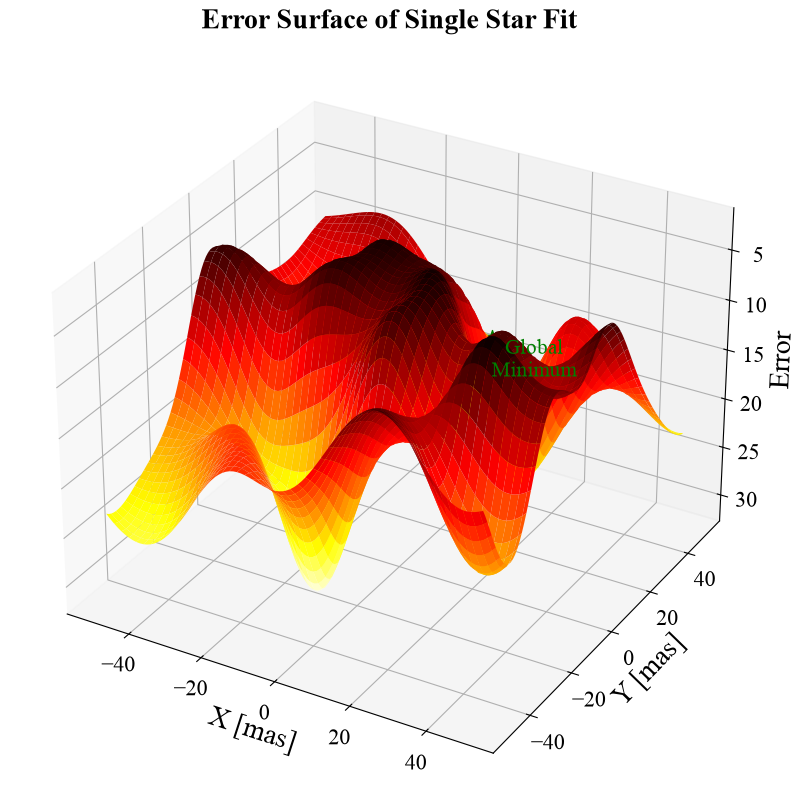

In [389]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot(projection='3d')

fig.suptitle('Error Surface of Single Star Fit')

surf = ax.plot_surface(XS, YS, deltas, cmap='hot')

ax.scatter(result.x[0], result.x[1], result.fun, marker='*', c='green', s=100, zorder=100)
ax.text(result.x[0], result.x[1], result.fun, s='Global\nMinimum', fontsize=15, va='top', color='green', ma='center', zorder=10)

ax.invert_zaxis()

ax.set_xlabel('X [mas]')
ax.set_ylabel('Y [mas]')
ax.set_zlabel('Error')

ax.set_aspect('equalxy')

plt.show()

### Now fitting a binary signal to the observed intensities
#### Four different stages:
1. Stage 1: Fit a single star like before using `scipy.optimize.differential_evolution` to get a starting point for Star 1.

2. Stage 2: Use the fitted single star position and a grid of Star 2 positions to find local minima and identify potential positions for Star 1 and Star 2 combined. This also solves the spectra using linear least squares.

3. Stage 3: Recover the spectra shapes by calculating the spectra using linear least squares for the optimized position found in Step 2. This will return the depth, center, and width of the spectra, as well as the mass of Star 2.

4. Refine all 8 fitted parameters with linear least squares to find parameter uncertainties and correlations.

Stage 1 (single star):  position = [7.76 0.14] mas, SSR = 1.182e+00


100%|██████████| 11/11 [01:15<00:00,  6.90s/it]


Stage 2 (binary):       positions = [ 1.999 -0.999 24.999  9.997] mas, SSR = 1.265e-05
Stage 3 (spectra):      star 1 line (F, depth, center, width) = [9.9980000e-01 9.0000000e-01 1.2828001e+03 9.9800000e-02]
                        star 2 line (F, depth, center, width) = [4.4380000e-01 7.9990000e-01 1.2828501e+03 8.0000000e-02]
                        M_2 = 0.8501 M_1

Stage 4 (joint fit):
                    fit  uncertainty    true
x1 [mas]        1.99925   0.00106378       2
y1 [mas]      -0.999304  0.000719401      -1
x2 [mas]        24.9992   0.00156196      25
y2 [mas]        9.99711   0.00196679      10
M2 [M_1]       0.850062  2.54598e-05    0.85
a_line_2       0.799857  0.000240981     0.8
center_2 [nm]   1282.85   0.00011317 1282.85
width_2 [nm]  0.0799937  0.000129756    0.08

Correlation matrix:
               x1 [mas]  y1 [mas]  x2 [mas]  y2 [mas]  M2 [M_1]  a_line_2  center_2 [nm]  width_2 [nm]
x1 [mas]           1.00     -0.11      0.32      0.08     -0.63     -0.03    

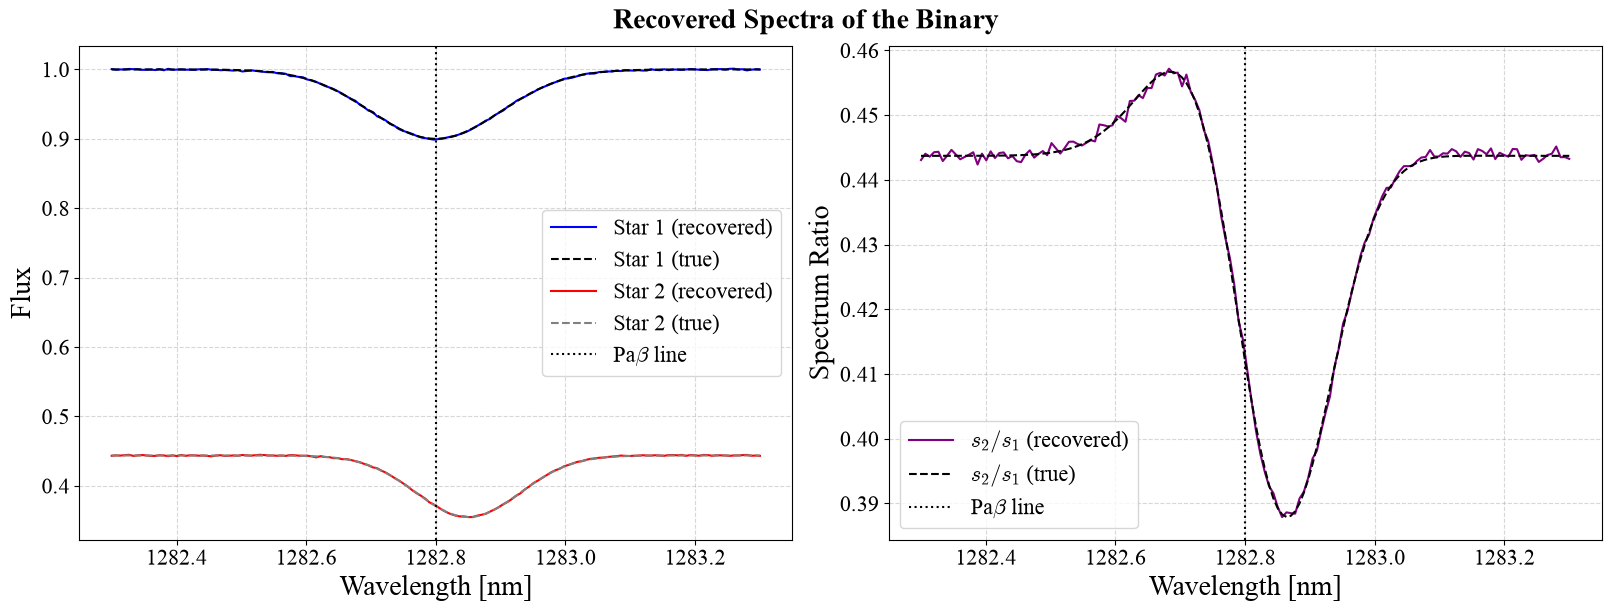

In [390]:
from scipy.optimize import least_squares

# ============================================================
# Example workflow: fitting a binary to the lantern outputs
# ============================================================
# Model: at every wavelength the port intensities are a linear combination of the two point-source responses,
#     I_n(λ) = s1(λ) G_n(θ1) + s2(λ) G_n(θ2)
# so for trial positions (θ1, θ2) the spectra s1(λ), s2(λ) follow from linear least squares.
# Order of the fit:
#   Stage 1: Single-star fit (differential_evolution) to get a starting point for star 1
#   Stage 2: Multistart local fits of the 4 positions (least_squares); spectra solved linearly inside
#   Stage 3: Recover s1(λ), s2(λ), s2/s1 and fit the line + mass of star 2 to the recovered spectrum
#   Stage 4: Joint refinement of all 8 parameters (least_squares) for uncertainties and parameter correlations

# ------------------------------------------------------------
# Test binary with known parameters (stands in for real data)
# ------------------------------------------------------------
def line_spectrum(F, a_line, center, width):
    '''Continuum F with a Gaussian absorption line of relative depth a_line at center [nm] with width [nm].'''
    return F * (1 - (1 - a_line) * np.exp(-0.5 * (WAV_RANGE - center)**2 / width**2))

TRUE_X1, TRUE_Y1 = 2, -1 # [mas]
TRUE_X2, TRUE_Y2 = 25, 10 # [mas]
TRUE_M2 = 0.85 # [M_1]
TRUE_A2, TRUE_C2, TRUE_W2 = 0.8, WAV_MIDDLE + 0.05, 0.08 # depth, center [nm], width [nm] of star 2's line

M_1, F_1 = 1, 1
true_s1 = line_spectrum(F_1, 0.9, WAV_MIDDLE, WAV_WIDTH)
true_s2 = line_spectrum(F_1 / functions.M_L_relation(M_1, TRUE_M2), TRUE_A2, TRUE_C2, TRUE_W2)

def port_response(x, y) -> np.ndarray:
    '''Port intensities (N_SPEC x N_OUTPUTS) for a unit, flat-spectrum point source at (x, y) [mas].'''
    projected = scene_projector.compute_point(x * MAS_TO_RAD, y * MAS_TO_RAD).repeat(N_SPEC, axis=2)
    return np.real(device.calculate_outputs(projected.transpose(2, 0, 1)))

rng = np.random.default_rng(0)
NOISE = 1e-3 # Fractional noise per channel and port

observed_intensities = true_s1[:, None] * port_response(TRUE_X1, TRUE_Y1) + true_s2[:, None] * port_response(TRUE_X2, TRUE_Y2)
observed_intensities *= 1 + NOISE * rng.standard_normal(observed_intensities.shape)

# What is measured: the fractional intensities and the total intensity at each wavelength
observed_total = observed_intensities.sum(axis=1) # (N_SPEC,)
observed_fractions = observed_intensities / observed_total[:, None] # (N_SPEC, N_OUTPUTS)

# ------------------------------------------------------------
# Inner linear solve: spectra for fixed positions
# ------------------------------------------------------------
def solve_spectra(G1, G2, fractions):
    '''
    Solves fractions(λ) ≈ a(λ) G1(λ) + b(λ) G2(λ) at every wavelength by linear least squares.

    Since fractions = I / sum(I), a = s1 / sum(I) and b = s2 / sum(I), so b / a = s2 / s1.

    Returns
    -------
    coeffs : np.ndarray
        (N_SPEC x 2) array of [a(λ), b(λ)]
    model : np.ndarray
        (N_SPEC x N_OUTPUTS) best-fit fractions
    '''
    A = np.stack([G1, G2], axis=2) # (N_SPEC, N_OUTPUTS, 2)
    AtA = np.einsum('lni,lnj->lij', A, A) # (N_SPEC, 2, 2)
    Atf = np.einsum('lni,ln->li', A, fractions) # (N_SPEC, 2)
    coeffs = np.linalg.solve(AtA, Atf[..., None])[..., 0] # (N_SPEC, 2)
    model = np.einsum('lni,li->ln', A, coeffs)
    return coeffs, model

def position_residuals(p, fractions) -> np.ndarray:
    '''Residual vector for positions p = (x1, y1, x2, y2) [mas], with the spectra solved linearly.'''
    _, model = solve_spectra(port_response(p[0], p[1]), port_response(p[2], p[3]), fractions)
    return (fractions - model).ravel()

# ------------------------------------------------------------
# Stage 1: single-star fit (starting point for star 1)
# ------------------------------------------------------------
def single_residuals(p, fractions) -> np.ndarray:
    '''Residual vector for a single star at p = (x, y) [mas]; its spectrum cancels in the fractions.'''
    G = port_response(p[0], p[1])
    return (fractions - G / G.sum(axis=1, keepdims=True)).ravel()

stage1 = differential_evolution(lambda p: np.sum(single_residuals(p, observed_fractions)**2), [(-50, 50), (-50, 50)], seed=0)
print(f'Stage 1 (single star):  position = {np.round(stage1.x, 2)} mas, SSR = {stage1.fun:.3e}')

# ------------------------------------------------------------
# Stage 2: multistart local fits of the 4 positions
# ------------------------------------------------------------
# The binary error surface has many local minima, so start star 2 from a coarse grid of positions
# and keep the best local fit
start_grid = np.arange(-75, 76, 15) # [mas]
min_start_separation = 10 # [mas]

best_fit = None
for x2_start in tqdm(start_grid):
    for y2_start in start_grid:
        if np.hypot(x2_start - stage1.x[0], y2_start - stage1.x[1]) < min_start_separation:
            continue

        fit = least_squares(position_residuals, np.r_[stage1.x, x2_start, y2_start], args=(observed_fractions,), x_scale=10)

        if best_fit is None or fit.cost < best_fit.cost:
            best_fit = fit

best_positions = best_fit.x
print(f'Stage 2 (binary):       positions = {np.round(best_positions, 3)} mas, SSR = {2*best_fit.cost:.3e}')

# ------------------------------------------------------------
# Stage 3: recover the spectra and fit star 2's line and mass
# ------------------------------------------------------------
coeffs, _ = solve_spectra(port_response(*best_positions[:2]), port_response(*best_positions[2:]), observed_fractions)

# The two stars are interchangeable in the model, so call the brighter one star 1
if np.median(coeffs[:, 1]) > np.median(coeffs[:, 0]):
    coeffs = coeffs[:, ::-1]
    best_positions = np.r_[best_positions[2:], best_positions[:2]]

spectrum_ratio = coeffs[:, 1] / coeffs[:, 0] # s2 / s1 (needs only the fractions)
recovered_s1 = coeffs[:, 0] * observed_total # Absolute spectra (also need the total intensity)
recovered_s2 = coeffs[:, 1] * observed_total

def fit_line(spectrum, guess):
    '''Fits (F, a_line, center, width) of line_spectrum to a recovered spectrum.'''
    return least_squares(lambda q: line_spectrum(*q) - spectrum, guess,
                         bounds=([0, 0, WAV_RANGE[0], 1e-3], [np.inf, 2, WAV_RANGE[-1], 1])).x

line1 = fit_line(recovered_s1, [np.median(recovered_s1), 0.9, WAV_MIDDLE, WAV_WIDTH])
line2 = fit_line(recovered_s2, [np.median(recovered_s2), 0.9, WAV_MIDDLE, WAV_WIDTH])

# Invert the mass-luminosity relation (M_1 < 2 branch): F_2 / F_1 = (M_2 / M_1)^5
fitted_M2 = M_1 * (line2[0] / line1[0])**(1/5)

print(f'Stage 3 (spectra):      star 1 line (F, depth, center, width) = {np.round(line1, 4)}')
print(f'                        star 2 line (F, depth, center, width) = {np.round(line2, 4)}')
print(f'                        M_2 = {fitted_M2:.4f} M_1')

# ------------------------------------------------------------
# Stage 4: joint refinement of all 8 parameters
# ------------------------------------------------------------
# Star 1's spectrum is held at its Stage 3 fit; the fractions only constrain s2 / s1
fitted_s1 = line_spectrum(*line1)

def binary_residuals(params, fractions) -> np.ndarray:
    '''Residual vector for params = (x1, y1, x2, y2, M2, a_line_2, center_2, width_2).'''
    x1, y1, x2, y2, M2, a2, c2, w2 = params
    s2 = line_spectrum(line1[0] / functions.M_L_relation(M_1, M2), a2, c2, w2)
    intensities = fitted_s1[:, None] * port_response(x1, y1) + s2[:, None] * port_response(x2, y2)
    return (fractions - intensities / intensities.sum(axis=1, keepdims=True)).ravel()

stage4 = least_squares(
    binary_residuals, np.r_[best_positions, fitted_M2, line2[1:]], args=(observed_fractions,),
    x_scale=[10, 10, 10, 10, 0.1, 0.1, 0.05, 0.05],
)

# Covariance from the Jacobian: C = (J^T J)^-1 * (residual variance)
n_data, n_params = stage4.fun.size, stage4.x.size
residual_variance = 2 * stage4.cost / (n_data - n_params)
covariance = np.linalg.inv(stage4.jac.T @ stage4.jac) * residual_variance
uncertainties = np.sqrt(np.diag(covariance))
correlation = covariance / np.outer(uncertainties, uncertainties)

param_names = ['x1 [mas]', 'y1 [mas]', 'x2 [mas]', 'y2 [mas]', 'M2 [M_1]', 'a_line_2', 'center_2 [nm]', 'width_2 [nm]']
true_values = [TRUE_X1, TRUE_Y1, TRUE_X2, TRUE_Y2, TRUE_M2, TRUE_A2, TRUE_C2, TRUE_W2]

print('\nStage 4 (joint fit):')
print(pd.DataFrame({'fit': stage4.x, 'uncertainty': uncertainties, 'true': true_values}, index=param_names).to_string(float_format='%.6g'))
print('\nCorrelation matrix:')
print(pd.DataFrame(correlation, index=param_names, columns=param_names).to_string(float_format='%.2f'))

# ------------------------------------------------------------
# Plotting recovered spectra
# ------------------------------------------------------------
fig = plt.figure(figsize=(16, 6))
fig.set_constrained_layout(True)
axes = fig.subplots(ncols=2)

fig.suptitle('Recovered Spectra of the Binary')

axes[0].plot(WAV_RANGE, recovered_s1, color='b', label='Star 1 (recovered)')
axes[0].plot(WAV_RANGE, true_s1, color='k', linestyle='--', label='Star 1 (true)')
axes[0].plot(WAV_RANGE, recovered_s2, color='r', label='Star 2 (recovered)')
axes[0].plot(WAV_RANGE, true_s2, color='gray', linestyle='--', label='Star 2 (true)')
axes[0].set_ylabel('Flux')

axes[1].plot(WAV_RANGE, spectrum_ratio, color='purple', label='$s_2/s_1$ (recovered)')
axes[1].plot(WAV_RANGE, true_s2 / true_s1, color='k', linestyle='--', label='$s_2/s_1$ (true)')
axes[1].set_ylabel('Spectrum Ratio')

for ax in axes:
    ax.axvline(WAV_MIDDLE, color='k', linestyle=':', label='Pa$\\beta$ line')
    ax.set_xlabel('Wavelength [nm]')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

plt.show()